# Patient satisfaction: exploration of selected hospital predictors

**Research question:** To what extent can hospital characteristics, quality-of-care measures, clinical outcomes, and Medicare spending predict overall patient satisfaction at U.S. hospitals?

This exploration is restricted to **Hospital Type, Hospital Ownership, Emergency Services, Mortality/Safety/Readmission performance, Hybrid_HWM, and MSPB-1**. The outcome is the overall hospital rating linear score. It examines availability and descriptive relationships; no prediction models, train/test splits, or imputation are performed. Joins below create a descriptive hospital-level table only.

In [1]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
DATA_FILES = {
    "hcahps": Path("data/HCAHPS-Hospital.csv"),
    "general": Path("data/Hospital_General_Information.csv"),
    "outcomes": Path("data/Complications_and_Deaths-Hospital.csv"),
    "spending": Path("data/Medicare_Hospital_Spending_Per_Patient-Hospital.csv"),
}
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")


Python 3.9.6 | pandas 2.3.3 | NumPy 2.0.2 | scikit-learn 1.6.1


## 1. Load and inspect the files

All columns are initially read as text. This preserves leading zeros in hospital identifiers and keeps CMS labels such as “Not Available” distinct from empty fields. Source files are not modified. File hashes identify exactly which downloads produced these results; the download dates and release dates were not provided.

In [2]:
datasets = {
    name: pd.read_csv(path, dtype="string", keep_default_na=False, encoding="utf-8-sig")
    for name, path in DATA_FILES.items()
}
file_summary = pd.DataFrame([
    {"dataset": name, "file": path.name, "rows": len(datasets[name]),
     "columns": datasets[name].shape[1],
     "unique_hospitals": datasets[name]["Facility ID"].nunique(),
     "blank_hospital_ids": int(datasets[name]["Facility ID"].str.strip().eq("").sum()),
     "exact_duplicate_rows": int(datasets[name].duplicated().sum()),
     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for name, path in DATA_FILES.items()
])
display(file_summary.drop(columns="sha256"))
display(file_summary[["file", "sha256"]])
for name, df in datasets.items():
    print(f"\n{name}: actual column names and loaded types")
    display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).to_numpy()}))
    display(df.head(2))


,dataset,file,rows,columns,unique_hospitals,blank_hospital_ids,exact_duplicate_rows
0,hcahps,HCAHPS-Hospital.csv,325720,22,4790,0,0
1,general,Hospital_General_Information.csv,5419,38,5419,0,0
2,outcomes,Complications_and_Deaths-Hospital.csv,95800,18,4790,0,0
3,spending,Medicare_Hospital_Spending_Per_Patient-Hospita...,4626,14,4626,0,0


,file,sha256
0,HCAHPS-Hospital.csv,b70e598f29552df302e30ed649d178abd1b3d3c868ae97...
1,Hospital_General_Information.csv,f874f09fef895a1ccf5bb7392dcbb2be05c9860339261b...
2,Complications_and_Deaths-Hospital.csv,2f7112969e2de2a015af8574848973dc48595ca6f2fe03...
3,Medicare_Hospital_Spending_Per_Patient-Hospita...,fcb050fecedd6af494750a7e6c46d992f2b03738f1f145...



hcahps: actual column names and loaded types


,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,HCAHPS Measure ID,string
9,HCAHPS Question,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description,Patient Survey Star Rating,Patient Survey Star Rating Footnote,HCAHPS Answer Percent,HCAHPS Answer Percent Footnote,HCAHPS Linear Mean Value,Number of Completed Surveys,Number of Completed Surveys Footnote,Survey Response Rate Percent,Survey Response Rate Percent Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_A_P,"Patients who reported that their nurses ""Alway...","Nurses ""always"" communicated well",Not Applicable,,76,,Not Applicable,1392,,17,,10/01/2024,09/30/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_SN_P,"Patients who reported that their nurses ""Somet...","Nurses ""sometimes"" or ""never"" communicated well",Not Applicable,,6,,Not Applicable,1392,,17,,10/01/2024,09/30/2025


...

,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,Measure ID,string
9,Measure Name,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Compared to National,Denominator,Score,Lower Estimate,Higher Estimate,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,COMP_HIP_KNEE,Rate of complications for hip/knee replacement...,Not Available,33,3.8,Not Available,Not Available,,04/01/2023,03/31/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,Not Available,4972,4.4,Not Available,Not Available,,07/01/2024,06/30/2025



spending: actual column names and loaded types


,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,Measure ID,string
9,Measure Name,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Score,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,MSPB-1,Medicare hospital spending per patient (Medica...,0.99,,01/01/2024,12/31/2024
1,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,(256) 593-8310,MSPB-1,Medicare hospital spending per patient (Medica...,1.00,,01/01/2024,12/31/2024


The files have different units of observation. General Information describes hospitals, while HCAHPS and Complications and Deaths contain multiple measures for each hospital. A repeated hospital identifier in these long-format datasets is expected; repeating the same hospital–measure pair would require investigation.

In [3]:
key_definitions = {"hcahps": ["Facility ID", "HCAHPS Measure ID"],
                   "general": ["Facility ID"],
                   "outcomes": ["Facility ID", "Measure ID"],
                   "spending": ["Facility ID", "Measure ID"]}
key_audit = pd.DataFrame([
    {"dataset": name, "key": " + ".join(keys),
     "rows_with_repeated_key": int(datasets[name].duplicated(keys, keep=False).sum())}
    for name, keys in key_definitions.items()
])
display(key_audit)


,dataset,key,rows_with_repeated_key
0,hcahps,Facility ID + HCAHPS Measure ID,0
1,general,Facility ID,0
2,outcomes,Facility ID + Measure ID,0
3,spending,Facility ID + Measure ID,0


## 2. Identify the satisfaction target

The target is the observed measure **`H_HSP_RATING_LINEAR_SCORE`**, labeled **“Overall hospital rating - linear mean score”**, using **`HCAHPS Linear Mean Value`**. This is separate from the star rating and the percentages of patients choosing individual rating categories. The intended scale is 0–100; the code checks the observed values against that range. No individual patient responses are available in these aggregate files.

In [4]:
hcahps = datasets["hcahps"]
rating_measures = hcahps.loc[
    hcahps["HCAHPS Measure ID"].str.startswith("H_HSP_RATING"),
    ["HCAHPS Measure ID", "HCAHPS Question", "HCAHPS Answer Description"]
].drop_duplicates()
display(rating_measures)
TARGET_MEASURE = "H_HSP_RATING_LINEAR_SCORE"
TARGET_COLUMN = "HCAHPS Linear Mean Value"
target_rows = hcahps.loc[hcahps["HCAHPS Measure ID"].eq(TARGET_MEASURE)].copy()
assert not target_rows.empty, "Target measure is absent."
assert not target_rows["Facility ID"].duplicated().any(), "Target is not unique per hospital."
raw_target = target_rows[TARGET_COLUMN].str.strip()
target_numeric = pd.to_numeric(raw_target, errors="coerce")
invalid = target_numeric.notna() & ~target_numeric.between(0, 100)
print("Target rows:", len(target_rows))
print("Numeric target values:", int(target_numeric.notna().sum()))
print("Missing/non-numeric target values:", int(target_numeric.isna().sum()))
print("Outside intended 0–100 range:", int(invalid.sum()))
display(raw_target[target_numeric.isna()].value_counts(dropna=False).to_frame("rows"))
display(target_numeric.describe().to_frame("hospital_rating_linear_score"))


,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description
57,H_HSP_RATING_0_6,Patients who gave their hospital a rating of 6...,"Patients who gave a rating of ""6"" or lower (low)"
58,H_HSP_RATING_7_8,Patients who gave their hospital a rating of 7...,"Patients who gave a rating of ""7"" or ""8"" (medium)"
59,H_HSP_RATING_9_10,Patients who gave their hospital a rating of 9...,"Patients who gave a rating of ""9"" or ""10"" (high)"
60,H_HSP_RATING_LINEAR_SCORE,Overall hospital rating - linear mean score,Overall hospital rating - linear mean score
61,H_HSP_RATING_STAR_RATING,Overall hospital rating - star rating,Overall hospital rating - star rating


Target rows: 4790
Numeric target values: 3183
Missing/non-numeric target values: 1607
Outside intended 0–100 range: 0


,rows
HCAHPS Linear Mean Value,
Not Available,1607


,hospital_rating_linear_score
count,3183.0
mean,87.880616
std,3.583284
min,69.0
25%,86.0
50%,88.0
75%,90.0
max,98.0


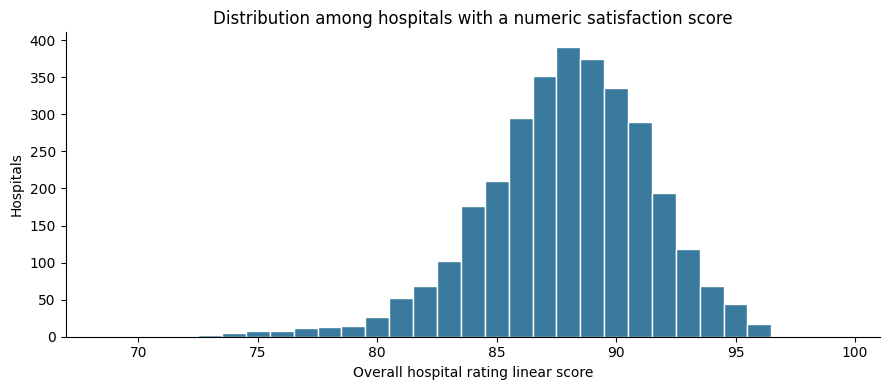

In [5]:
fig, ax = plt.subplots()
ax.hist(target_numeric.dropna().astype(float), bins=np.arange(68.5, 100.5, 1), edgecolor="white", color="#397a9e")
ax.set(xlabel="Overall hospital rating linear score", ylabel="Hospitals",
       title="Distribution among hospitals with a numeric satisfaction score")
plt.tight_layout()
plt.show()


In [6]:
display(Markdown(
    f"**Target findings.** {target_numeric.notna().sum():,} of {len(target_rows):,} hospitals "
    f"({target_numeric.notna().mean():.1%}) have numeric scores; "
    f"{target_numeric.isna().sum():,} ({target_numeric.isna().mean():.1%}) do not. "
    f"Among reported scores, the mean is {target_numeric.mean():.2f}, the median is "
    f"{target_numeric.median():.1f}, and the observed range is "
    f"{target_numeric.min():.0f}–{target_numeric.max():.0f}. "
    "These summaries exclude unavailable scores and should not be interpreted as the satisfaction of hospitals without reported scores."
))


**Target findings.** 3,183 of 4,790 hospitals (66.5%) have numeric scores; 1,607 (33.5%) do not. Among reported scores, the mean is 87.88, the median is 88.0, and the observed range is 69–98. These summaries exclude unavailable scores and should not be interpreted as the satisfaction of hospitals without reported scores.

## 3. Select the agreed predictors

The three hospital characteristics come from General Information. For Mortality, Safety, and Readmission performance, the source provides counts of measures rated Better, No Different, or Worse. Each group is summarized as **Better ÷ (Better + No Different + Worse)**. This is the proportion of *classified* measures rated better, not a patient outcome rate. It avoids treating an unclassified measure as a poor result. The number of classified measures and the facility measure count are retained for audit. A zero denominator produces a missing proportion.

Only `Hybrid_HWM` and `MSPB-1` are selected from the outcome and spending files. Their numeric values come from `Score`. Other individual clinical measures, other HCAHPS measures, and the overall hospital star rating are excluded from predictor analysis.

In [7]:
general = datasets["general"]
characteristics = ["Hospital Type", "Hospital Ownership", "Emergency Services"]
performance_groups = {"Mortality": "MORT", "Safety": "Safety", "Readmission": "READM"}
raw_performance_columns = [
    column for prefix in performance_groups.values()
    for column in [f"Count of Facility {prefix} Measures", f"Count of {prefix} Measures Better",
                   f"Count of {prefix} Measures No Different", f"Count of {prefix} Measures Worse"]
]
selected_general = general[["Facility ID"] + characteristics + raw_performance_columns].copy()
assert selected_general["Facility ID"].is_unique
performance_audit = []
performance_features = []
for group, prefix in performance_groups.items():
    count_cols = [f"Count of {prefix} Measures {label}" for label in ["Better", "No Different", "Worse"]]
    counts = selected_general[count_cols].apply(pd.to_numeric, errors="coerce")
    classified = counts.sum(axis=1, min_count=3)
    facility_count = pd.to_numeric(selected_general[f"Count of Facility {prefix} Measures"], errors="coerce")
    feature = f"{group} better proportion"
    performance_features.append(feature)
    selected_general[feature] = counts.iloc[:, 0].div(classified.where(classified.gt(0)))
    selected_general[f"{group} classified measures"] = classified
    comparable = classified.notna() & facility_count.notna()
    performance_audit.append({"group": group, "hospitals_with_zero_classified": int(classified.eq(0).sum()),
                              "hospitals_with_incomplete_counts": int(counts.isna().any(axis=1).sum()),
                              "classified_differs_from_facility_count": int((comparable & classified.ne(facility_count)).sum())})
display(pd.DataFrame(performance_audit))

def select_measure(dataset_name, measure_id, output_name):
    selected = datasets[dataset_name].loc[datasets[dataset_name]["Measure ID"].eq(measure_id)].copy()
    assert not selected.empty, f"Missing measure: {measure_id}"
    assert selected["Facility ID"].is_unique, f"Repeated hospital rows for {measure_id}"
    selected[output_name] = pd.to_numeric(selected["Score"].str.strip(), errors="coerce")
    return selected

hybrid = select_measure("outcomes", "Hybrid_HWM", "Hybrid_HWM")
spending = select_measure("spending", "MSPB-1", "MSPB-1")
for name, selected in [("Hybrid_HWM", hybrid), ("MSPB-1", spending)]:
    display(selected[["Measure ID", "Measure Name", "Start Date", "End Date"]].drop_duplicates())
    print(f"{name}: nonnumeric score labels")
    display(selected.loc[selected[name].isna(), "Score"].value_counts().to_frame("rows"))


,group,hospitals_with_zero_classified,hospitals_with_incomplete_counts,classified_differs_from_facility_count
0,Mortality,0,1323,0
1,Safety,0,2075,0
2,Readmission,0,1155,0


,Measure ID,Measure Name,Start Date,End Date
1,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,07/01/2024,06/30/2025


Hybrid_HWM: nonnumeric score labels


,rows
Score,
Not Available,529


,Measure ID,Measure Name,Start Date,End Date
0,MSPB-1,Medicare hospital spending per patient (Medica...,01/01/2024,12/31/2024


MSPB-1: nonnumeric score labels


,rows
Score,
Not Available,1754


## 4. Build a descriptive hospital-level table and check coverage

General Information defines the reference hospital list. Left joins preserve all those hospitals, including hospitals without satisfaction scores. Every join is checked as one-to-one; unmatched hospitals are reported. Missing targets and missing predictors remain missing. The target's original reporting status is kept separate from an absent HCAHPS target row.

In [8]:
target_view = target_rows[["Facility ID", "Start Date", "End Date"]].copy()
target_view["Hospital rating linear score"] = target_numeric
target_view["target_row_present"] = True
analysis = selected_general.merge(target_view[["Facility ID", "Hospital rating linear score", "target_row_present"]],
                                 on="Facility ID", how="left", validate="one_to_one")
for selected, feature in [(hybrid, "Hybrid_HWM"), (spending, "MSPB-1")]:
    analysis = analysis.merge(selected[["Facility ID", feature]], on="Facility ID", how="left", validate="one_to_one")
features = characteristics + performance_features + ["Hybrid_HWM", "MSPB-1"]
for col in characteristics:
    cleaned = analysis[col].str.strip()
    analysis[col] = cleaned.mask(cleaned.str.casefold().isin(["", "not available", "not applicable"]))
coverage = pd.DataFrame([
    {"selected_measure": name, "source_hospitals": selected["Facility ID"].nunique(),
     "outside_reference_list": int((~selected["Facility ID"].isin(general["Facility ID"])).sum())}
    for name, selected in [("Target", target_view), ("Hybrid_HWM", hybrid), ("MSPB-1", spending)]
])
display(coverage)
print("Reference hospitals:", len(analysis))
print("No HCAHPS target row:", int(analysis["target_row_present"].isna().sum()))
print("Present target row but no numeric target:", int((analysis["target_row_present"].eq(True) & analysis["Hospital rating linear score"].isna()).sum()))
periods = []
for label, frame in [("Target", target_view), ("Hybrid_HWM", hybrid), ("MSPB-1", spending)]:
    part = frame[["Start Date", "End Date"]].drop_duplicates().copy()
    part.insert(0, "measure", label)
    periods.append(part)
display(pd.concat(periods, ignore_index=True))


,selected_measure,source_hospitals,outside_reference_list
0,Target,4790,0
1,Hybrid_HWM,4790,0
2,MSPB-1,4626,0


Reference hospitals: 5419
No HCAHPS target row: 629
Present target row but no numeric target: 1607


,measure,Start Date,End Date
0,Target,10/01/2024,09/30/2025
1,Hybrid_HWM,07/01/2024,06/30/2025
2,MSPB-1,01/01/2024,12/31/2024


## 5. Missingness in the selected predictors

Availability is shown for all reference hospitals and separately for hospitals with a numeric target—the subset that could support a later supervised analysis. Missing values here include absent measure rows as well as present rows with unavailable numeric values. Raw General Information counts and their labels are audited separately; none are imputed.

,all_hospitals,missing_all,missing_all_percent,hospitals_with_target,missing_with_target,missing_with_target_percent
Hospital Type,5419,0,0.000000,3183,0,0.000000
Hospital Ownership,5419,0,0.000000,3183,0,0.000000
Emergency Services,5419,0,0.000000,3183,0,0.000000
Mortality better proportion,5419,1323,24.414099,3183,52,1.633679
Safety better proportion,5419,2075,38.291198,3183,161,5.058121
Readmission better proportion,5419,1155,21.313896,3183,45,1.413761
Hybrid_HWM,5419,1158,21.369256,3183,35,1.099592
MSPB-1,5419,2547,47.001292,3183,554,17.404964


Count of Facility MORT Measures nonnumeric labels: {'Not Available': 1323}
Count of MORT Measures Better nonnumeric labels: {'Not Available': 1323}
Count of MORT Measures No Different nonnumeric labels: {'Not Available': 1323}
Count of MORT Measures Worse nonnumeric labels: {'Not Available': 1323}


Count of Facility Safety Measures nonnumeric labels: {'Not Available': 2075}
Count of Safety Measures Better nonnumeric labels: {'Not Available': 2075}
Count of Safety Measures No Different nonnumeric labels: {'Not Available': 2075}
Count of Safety Measures Worse nonnumeric labels: {'Not Available': 2075}
Count of Facility READM Measures nonnumeric labels: {'Not Available': 1155}
Count of READM Measures Better nonnumeric labels: {'Not Available': 1155}
Count of READM Measures No Different nonnumeric labels: {'Not Available': 1155}
Count of READM Measures Worse nonnumeric labels: {'Not Available': 1155}
Hospitals with target and every selected predictor: 2612


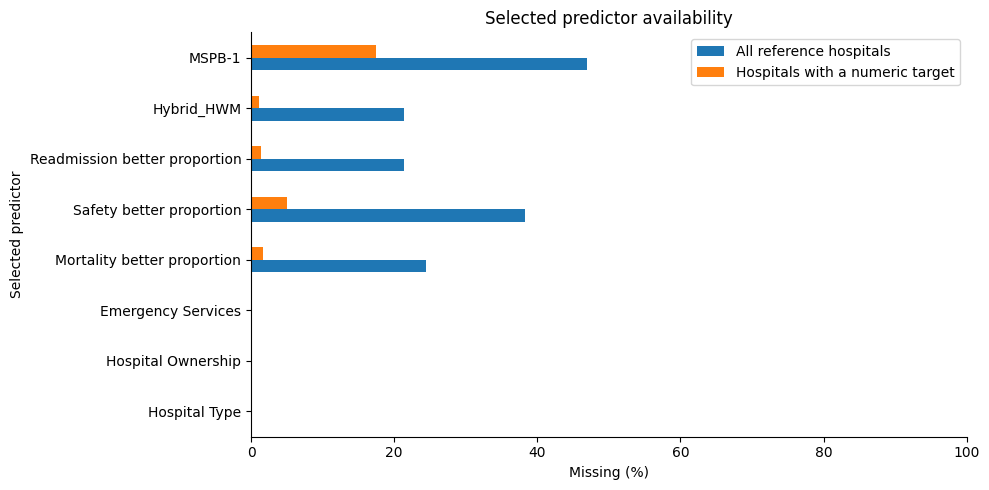

In [9]:
scored = analysis.loc[analysis["Hospital rating linear score"].notna()].copy()
availability = pd.DataFrame({
    "all_hospitals": len(analysis),
    "missing_all": analysis[features].isna().sum(),
    "missing_all_percent": analysis[features].isna().mean() * 100,
    "hospitals_with_target": len(scored),
    "missing_with_target": scored[features].isna().sum(),
    "missing_with_target_percent": scored[features].isna().mean() * 100,
})
display(availability)
for col in raw_performance_columns:
    raw = general[col].str.strip()
    labels = raw[pd.to_numeric(raw, errors="coerce").isna()].value_counts(dropna=False)
    print(col, "nonnumeric labels:", labels.to_dict())
complete_count = int(scored[features].notna().all(axis=1).sum())
print("Hospitals with target and every selected predictor:", complete_count)
ax = availability[["missing_all_percent", "missing_with_target_percent"]].plot.barh(figsize=(10, 5))
ax.set(xlim=(0, 100), xlabel="Missing (%)", ylabel="Selected predictor", title="Selected predictor availability")
ax.legend(["All reference hospitals", "Hospitals with a numeric target"])
plt.tight_layout()
plt.show()


## 6. Satisfaction by hospital characteristics

Tables show both total hospital counts and counts with a reported target. Means, medians, and boxplots use numeric targets only. Differences are descriptive and can reflect patient populations, geography, hospital size, and reporting patterns. They are not adjusted effects.

Hospital Type


,hospitals,numeric_targets,mean_score,median_score,target_available_percent
Hospital Type,,,,,
Acute Care - Department of Defense,32,27,91.37,91.0,84.38
Acute Care - Veterans Administration,132,110,90.45,90.5,83.33
Acute Care Hospitals,3107,2699,87.3,88.0,86.87
Childrens,94,0,<NA>,<NA>,0.0
Critical Access Hospitals,1382,347,91.32,91.0,25.11
Long-term,5,0,<NA>,<NA>,0.0
Psychiatric,624,0,<NA>,<NA>,0.0
Rural Emergency Hospital,43,0,<NA>,<NA>,0.0


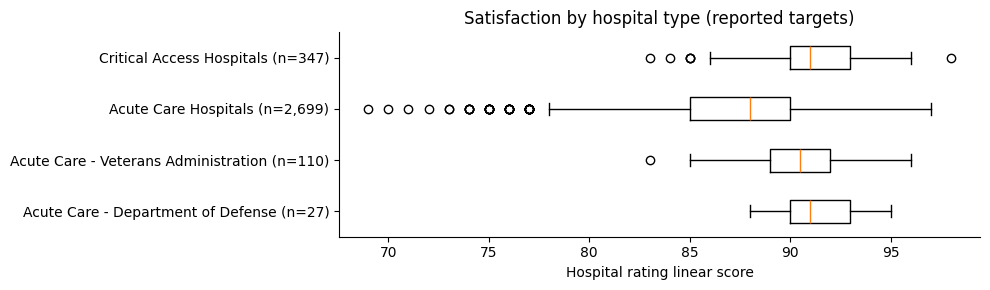

Hospital Ownership


,hospitals,numeric_targets,mean_score,median_score,target_available_percent
Hospital Ownership,,,,,
Department of Defense,32,27,91.37,91.0,84.38
Government - Federal,42,12,87.58,87.5,28.57
Government - Hospital District or Authority,512,204,88.17,88.0,39.84
Government - Local,393,154,88.79,89.0,39.19
Government - State,209,39,87.64,88.0,18.66
Physician,80,50,91.28,92.0,62.5
Proprietary,1063,518,85.84,86.0,48.73
Tribal,17,3,90.33,90.0,17.65
Veterans Health Administration,132,110,90.45,90.5,83.33


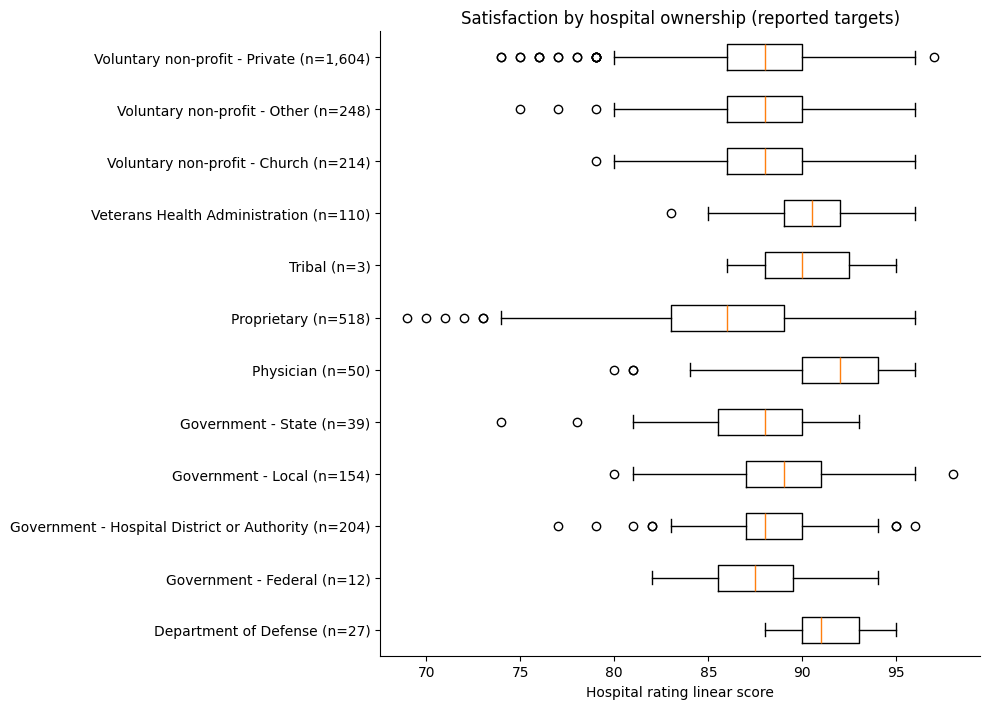

Emergency Services


,hospitals,numeric_targets,mean_score,median_score,target_available_percent
Emergency Services,,,,,
No,924,192,88.95,90.0,20.78
Yes,4495,2991,87.81,88.0,66.54


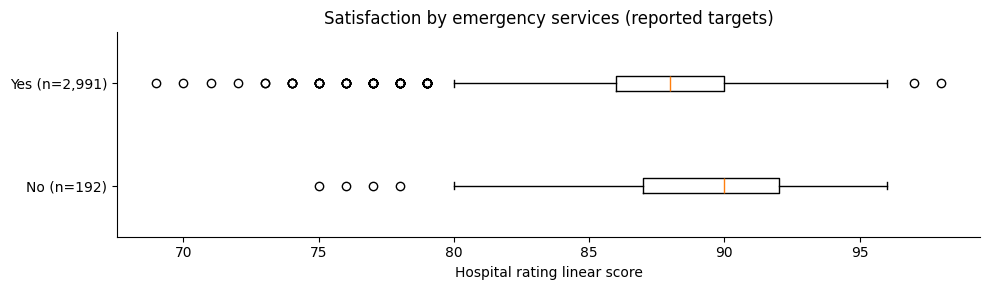

In [10]:
characteristic_summaries = {}
for col in characteristics:
    group_labels = analysis[col].fillna("Missing / unavailable")
    summary = analysis.groupby(group_labels)["Hospital rating linear score"].agg(
        hospitals="size", numeric_targets="count", mean_score="mean", median_score="median")
    summary["target_available_percent"] = 100 * summary["numeric_targets"] / summary["hospitals"]
    characteristic_summaries[col] = summary
    print(col)
    display(summary.round(2))
    groups = [(label, group["Hospital rating linear score"].dropna().astype(float))
              for label, group in analysis.groupby(group_labels)]
    groups = [(label, values) for label, values in groups if len(values)]
    fig, ax = plt.subplots(figsize=(10, max(3, .6 * len(groups))))
    ax.boxplot([values for _, values in groups], vert=False,
               tick_labels=[f"{label} (n={len(values):,})" for label, values in groups])
    ax.set(xlabel="Hospital rating linear score", title=f"Satisfaction by {col.lower()} (reported targets)")
    plt.tight_layout()
    plt.show()


## 7. Satisfaction and numeric predictors

Mortality/Safety/Readmission performance is represented by the better proportion defined above. `Hybrid_HWM` is the reported hybrid hospital-wide mortality measure; `MSPB-1` is the reported spending score. Both are taken directly from their selected score rows, with no fabricated values.

Each scatterplot uses hospitals with both the predictor and the target. Pearson correlation summarizes linear association; Spearman correlation summarizes rank association. Sample sizes differ by predictor. The correlations are unadjusted exploratory summaries and do not measure predictive accuracy or causation. If a predictor has no usable variation or too few observations, its correlation is left undefined.

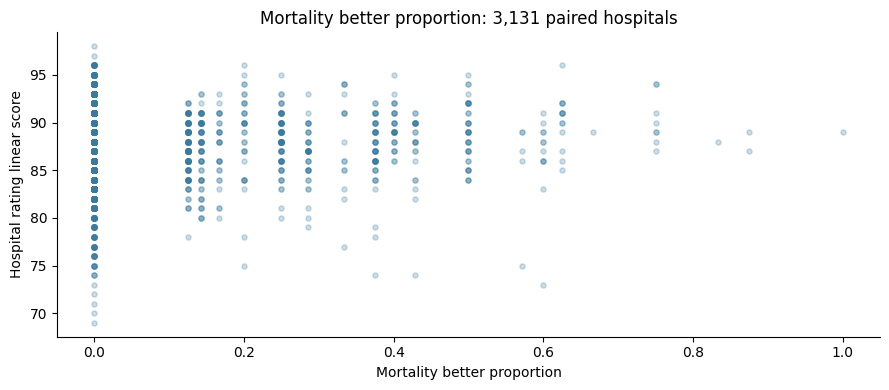

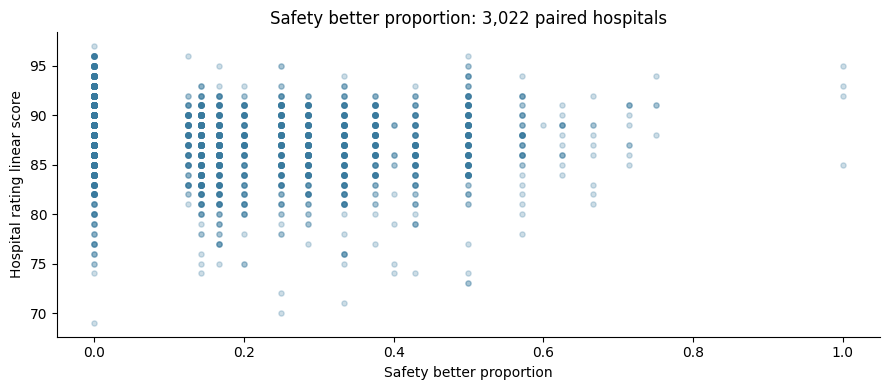

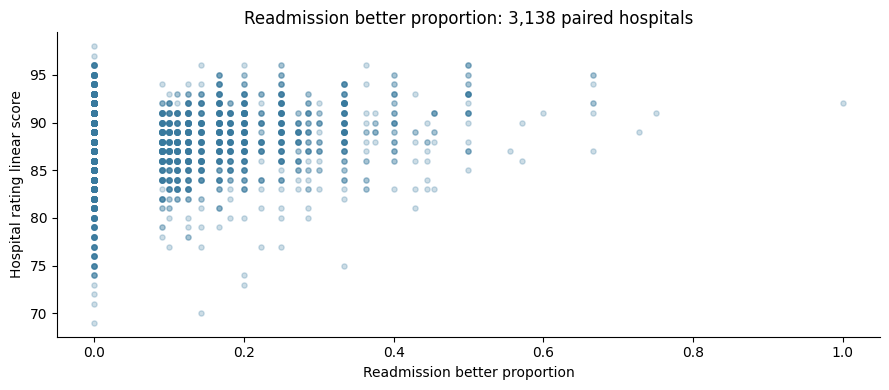

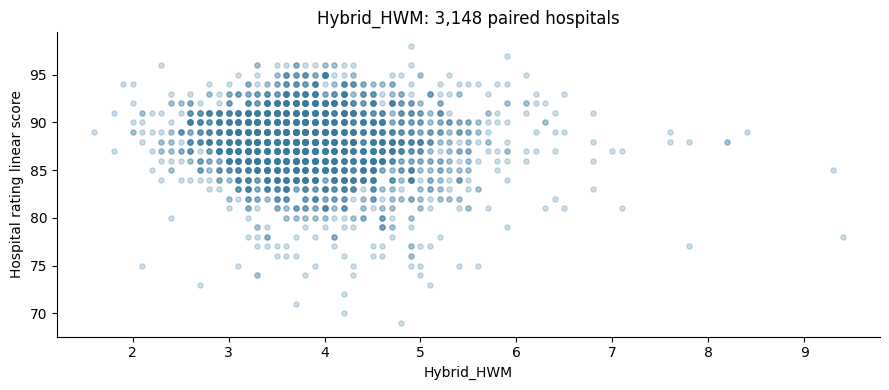

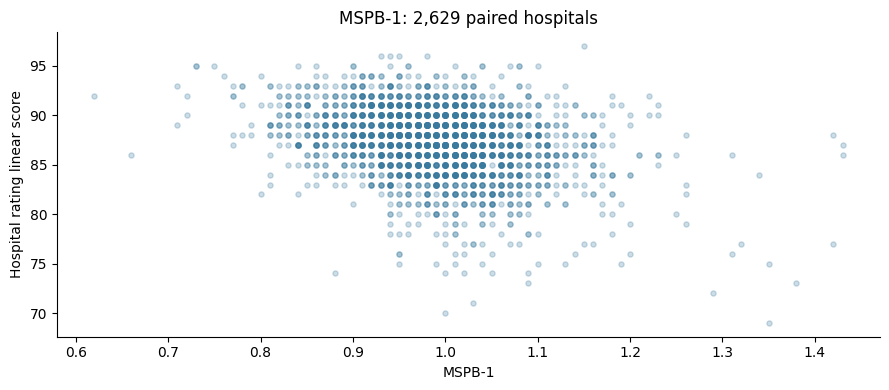

,paired_hospitals,predictor_min,predictor_max,pearson_r,spearman_rho
predictor,,,,,
Mortality better proportion,3131,0.00,1.00,0.019,-0.000
Safety better proportion,3022,0.00,1.00,-0.200,-0.263
Readmission better proportion,3138,0.00,1.00,0.174,0.149
Hybrid_HWM,3148,1.60,9.40,-0.076,-0.056
MSPB-1,2629,0.62,1.43,-0.313,-0.286


In [11]:
numeric_features = performance_features + ["Hybrid_HWM", "MSPB-1"]
relationships = []
for feature in numeric_features:
    pair = scored[[feature, "Hospital rating linear score"]].dropna().astype(float)
    usable = len(pair) >= 3 and pair[feature].nunique() > 1 and pair.iloc[:, 1].nunique() > 1
    relationships.append({"predictor": feature, "paired_hospitals": len(pair),
                          "predictor_min": pair[feature].min(), "predictor_max": pair[feature].max(),
                          "pearson_r": pair[feature].corr(pair.iloc[:, 1]) if usable else np.nan,
                          "spearman_rho": pair[feature].corr(pair.iloc[:, 1], method="spearman") if usable else np.nan})
    fig, ax = plt.subplots()
    if len(pair):
        ax.scatter(pair[feature], pair.iloc[:, 1], alpha=.25, s=14, color="#397a9e")
    ax.set(xlabel=feature, ylabel="Hospital rating linear score", title=f"{feature}: {len(pair):,} paired hospitals")
    if not usable:
        ax.text(.5, .5, "Insufficient observations or variation for correlation", transform=ax.transAxes, ha="center")
    plt.tight_layout()
    plt.show()
relationships = pd.DataFrame(relationships).set_index("predictor")
display(relationships.round(3))


In [12]:
display(Markdown("## Findings for the selected predictors"))
display(Markdown(
    f"The reference population contains **{len(analysis):,} hospitals**, of which **{len(scored):,}** have a numeric satisfaction score. "
    f"Only **{complete_count:,}** have both a numeric target and all eight selected predictor summaries. "
    "This is an availability count; no complete-case sample is imposed and no rows are dropped from the reference table."
))
for feature, row in relationships.iterrows():
    if pd.notna(row["pearson_r"]):
        display(Markdown(f"- **{feature}:** {int(row['paired_hospitals']):,} paired hospitals; "
                         f"Pearson r = {row['pearson_r']:.3f}, Spearman rho = {row['spearman_rho']:.3f}."))
    else:
        display(Markdown(f"- **{feature}:** {int(row['paired_hospitals']):,} paired hospitals; "
                         "a correlation cannot be estimated because the sample or variation is insufficient."))
display(Markdown(
    "**Interpretation and limits.** A positive correlation means higher values tend to accompany higher satisfaction; "
    "a negative value means the opposite. These associations use different hospital subsets and should not be ranked as independent effects. "
    "A better proportion of zero means no classified measures were rated better; it does not mean all were rated worse. "
    "For small denominators a single measure changes the proportion substantially. "
    "Different measurement periods and nonrandom reporting limit comparisons. "
    "The extent of predictive performance remains unanswered at this stage: no prediction models have been fitted."
))


## Findings for the selected predictors

The reference population contains **5,419 hospitals**, of which **3,183** have a numeric satisfaction score. Only **2,612** have both a numeric target and all eight selected predictor summaries. This is an availability count; no complete-case sample is imposed and no rows are dropped from the reference table.

- **Mortality better proportion:** 3,131 paired hospitals; Pearson r = 0.019, Spearman rho = -0.000.

- **Safety better proportion:** 3,022 paired hospitals; Pearson r = -0.200, Spearman rho = -0.263.

- **Readmission better proportion:** 3,138 paired hospitals; Pearson r = 0.174, Spearman rho = 0.149.

- **Hybrid_HWM:** 3,148 paired hospitals; Pearson r = -0.076, Spearman rho = -0.056.

- **MSPB-1:** 2,629 paired hospitals; Pearson r = -0.313, Spearman rho = -0.286.

**Interpretation and limits.** A positive correlation means higher values tend to accompany higher satisfaction; a negative value means the opposite. These associations use different hospital subsets and should not be ranked as independent effects. A better proportion of zero means no classified measures were rated better; it does not mean all were rated worse. For small denominators a single measure changes the proportion substantially. Different measurement periods and nonrandom reporting limit comparisons. The extent of predictive performance remains unanswered at this stage: no prediction models have been fitted.

## 8. Resolve missing values for subsequent analysis

**Target:** Hospitals without a numeric satisfaction target are excluded from the supervised sample. Targets are never imputed: invented satisfaction labels would undermine evaluation. The original `analysis` dataframe and earlier descriptive results are retained. Missing targets include both absent HCAHPS rows and rows labeled “Not Available”.

**Predictors:** Hospitals with missing predictors are retained. Numeric predictors use training-set medians and missingness indicators; categorical predictors use an explicit `Missing` category. Indicators allow a later model to distinguish an observed value from an imputed value. A missing performance proportion stays distinct from an observed zero.

To produce usable filled tables without leaking information, an 80/20 hospital split is created solely for data preparation, with a fixed random seed. The imputer learns medians from the training portion only and applies those same medians to the held-out portion. No prediction models are fitted or evaluated. For future cross-validation, the separate, unfitted `preprocessor` must be included inside a model pipeline so medians are relearned in each training fold; the pre-imputed tables must not be used for cross-validation.

Median imputation is a practical starting policy, not proof that missingness is random. Reporting-related selection remains a limitation. The stored hospital IDs are retained separately from predictor values.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

TARGET = "Hospital rating linear score"
model_data = analysis.loc[analysis[TARGET].notna(), ["Facility ID", TARGET] + features].copy()
assert model_data["Facility ID"].is_unique
assert model_data[TARGET].between(0, 100).all()

# Keep raw predictors for future fold-specific preprocessing.
X = model_data.set_index("Facility ID")[features].copy()
y = model_data.set_index("Facility ID")[TARGET].astype(float)
for column in numeric_features:
    X[column] = pd.to_numeric(X[column], errors="coerce").astype(float)
for column in characteristics:
    values = X[column].astype(object)
    X[column] = values.where(pd.notna(values), np.nan)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
if X_train[numeric_features].isna().all().any():
    raise ValueError("A numeric predictor has no training values; a median cannot be estimated.")

# This template remains unfitted for use inside a future model pipeline.
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_features),
    ("categorical", SimpleImputer(strategy="constant", fill_value="Missing"), characteristics),
], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

# Fit a separate copy for these train/test preparation tables only.
fitted_preprocessor = clone(preprocessor)
X_train_prepared = fitted_preprocessor.fit_transform(X_train)
X_test_prepared = fitted_preprocessor.transform(X_test)
assert not X_train_prepared.isna().any().any()
assert not X_test_prepared.isna().any().any()
assert y_train.notna().all() and y_test.notna().all()
assert set(X_train.index).isdisjoint(X_test.index)
assert X_train_prepared.index.equals(y_train.index)
assert X_test_prepared.index.equals(y_test.index)

sample_flow = pd.DataFrame({
    "stage": ["All reference hospitals", "Excluded: missing target", "Retained: numeric target",
              "Retained with at least one missing predictor", "Training hospitals", "Held-out hospitals"],
    "hospitals": [len(analysis), int(analysis[TARGET].isna().sum()), len(model_data),
                  int(X.isna().any(axis=1).sum()), len(X_train), len(X_test)]
})
display(sample_flow)
imputation_audit = pd.DataFrame({
    "missing_train_before": X_train.isna().sum(),
    "missing_test_before": X_test.isna().sum(),
    "missing_train_after": X_train_prepared[features].isna().sum(),
    "missing_test_after": X_test_prepared[features].isna().sum(),
})
display(imputation_audit)
display(pd.Series(fitted_preprocessor.named_transformers_["numeric"].statistics_,
                  index=numeric_features, name="Training-only replacement median").to_frame())
print("Prepared predictor columns:", X_train_prepared.columns.tolist())
display(X_train_prepared.head())
display(Markdown(
    f"**Missing-value handling completed.** {analysis[TARGET].isna().sum():,} reference hospitals without a numeric target "
    f"are excluded from the supervised sample. All {len(model_data):,} hospitals with numeric targets are retained, "
    f"including {X.isna().any(axis=1).sum():,} with incomplete predictors. "
    f"The prepared training ({len(X_train):,}) and held-out ({len(X_test):,}) predictor tables contain no missing values. "
    "The original dataframe and raw predictors remain available. Categories are not yet encoded, and no prediction model or cross-validation has been run."
))


,stage,hospitals
0,All reference hospitals,5419
1,Excluded: missing target,2236
2,Retained: numeric target,3183
3,Retained with at least one missing predictor,571
4,Training hospitals,2546
5,Held-out hospitals,637


,missing_train_before,missing_test_before,missing_train_after,missing_test_after
Hospital Type,0,0,0,0
Hospital Ownership,0,0,0,0
Emergency Services,0,0,0,0
Mortality better proportion,42,10,0,0
Safety better proportion,128,33,0,0
Readmission better proportion,36,9,0,0
Hybrid_HWM,26,9,0,0
MSPB-1,436,118,0,0


,Training-only replacement median
Mortality better proportion,0.000000
Safety better proportion,0.142857
Readmission better proportion,0.000000
Hybrid_HWM,3.800000
MSPB-1,0.990000


Prepared predictor columns: ['Mortality better proportion', 'Safety better proportion', 'Readmission better proportion', 'Hybrid_HWM', 'MSPB-1', 'missingindicator_Mortality better proportion', 'missingindicator_Safety better proportion', 'missingindicator_Readmission better proportion', 'missingindicator_Hybrid_HWM', 'missingindicator_MSPB-1', 'Hospital Type', 'Hospital Ownership', 'Emergency Services']


,Mortality better proportion,Safety better proportion,Readmission better proportion,Hybrid_HWM,MSPB-1,missingindicator_Mortality better proportion,missingindicator_Safety better proportion,missingindicator_Readmission better proportion,missingindicator_Hybrid_HWM,missingindicator_MSPB-1,Hospital Type,Hospital Ownership,Emergency Services
Facility ID,,,,,,,,,,,,,
531318,0.0,0.142857,0.0,4.0,0.99,1.0,1.0,1.0,0.0,1.0,Critical Access Hospitals,Government - Hospital District or Authority,Yes
090001,0.0,0.250000,0.0,3.5,0.98,0.0,0.0,0.0,0.0,0.0,Acute Care Hospitals,Proprietary,Yes
440218,0.0,0.142857,0.0,3.4,0.99,1.0,1.0,1.0,0.0,1.0,Acute Care Hospitals,Voluntary non-profit - Other,No
440176,0.0,0.000000,0.0,3.9,0.99,0.0,0.0,0.0,0.0,0.0,Acute Care Hospitals,Voluntary non-profit - Private,Yes
300012,0.0,0.125000,0.1,4.9,1.01,0.0,0.0,0.0,0.0,0.0,Acute Care Hospitals,Voluntary non-profit - Private,Yes


**Missing-value handling completed.** 2,236 reference hospitals without a numeric target are excluded from the supervised sample. All 3,183 hospitals with numeric targets are retained, including 571 with incomplete predictors. The prepared training (2,546) and held-out (637) predictor tables contain no missing values. The original dataframe and raw predictors remain available. Categories are not yet encoded, and no prediction model or cross-validation has been run.

## Sources and limits

The supplied local CSVs are the source for all counts, dates, and descriptive statistics above. Their SHA-256 hashes are recorded near the start. Download and release dates were not supplied, so they are not inferred.

- [CMS hospital data catalog](https://data.cms.gov/provider-data/topics/hospitals)
- [CMS HCAHPS hospital dataset](https://data.cms.gov/provider-data/dataset/dgck-syfz)
- [CMS HCAHPS overview](https://www.cms.gov/data-research/research/consumer-assessment-healthcare-providers-systems/hospital-cahps-hcahps)

The intended 0–100 target scale comes from the project specification; the observed values and labels are verified in the CSV. The accompanying release dictionary was not included in the supplied files. Any later feature selection should consider information leakage: the CMS overall hospital star rating includes patient experience, and other HCAHPS measures share the same survey as the target. This notebook does not use those fields to predict the target.